In [ ]:
!pip install pandas numpy scipy statsmodels matplotlib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import os

DATA_DIR = "/content/drive/MyDrive/GSE149009"
RESULTS_DIR = f"{DATA_DIR}/results/survival"

os.makedirs(RESULTS_DIR, exist_ok=True)

clinical = pd.read_csv(
    f"{DATA_DIR}/GSE149009_clean_clinical_metadata.csv"
)

expression = pd.read_csv(
    f"{DATA_DIR}/GSE149009_gbm_rna_deseq2.txt",
    sep="\t",
    index_col=0
)

print("Clinical shape:", clinical.shape)
print("Expression shape:", expression.shape)

Clinical shape: (68, 12)
Expression shape: (37361, 68)


In [ ]:
clinical_survival = clinical.dropna(
    subset=["survival_days"]
).copy()

samples = clinical_survival["expr_column"].tolist()

expression_survival = expression[samples]

survival = clinical_survival["survival_days"].astype(float).to_numpy()

print("Samples used:", len(samples))
print("Genes tested:", expression_survival.shape[0])
print("Survival values:", len(survival))

Samples used: 59
Genes tested: 37361
Survival values: 59


In [ ]:
assert len(samples) == 59
assert expression_survival.shape[1] == 59
assert len(survival) == 59
assert expression_survival.columns.tolist() == samples

print("Survival cohort and expression matrix verified.")

Survival cohort and expression matrix verified.


In [ ]:
results = []

constant_genes = 0

for gene in expression_survival.index:
    values = expression_survival.loc[gene].astype(float).to_numpy()

    # Remove genes with effectively no variation
    if np.std(values) < 1e-10:
        constant_genes += 1
        continue

    rho, p = spearmanr(values, survival)

    results.append({
        "gene": gene,
        "spearman_rho": rho,
        "p_value": p
    })

results = pd.DataFrame(results)

print("Genes tested:", len(results))
print("Effectively constant genes removed:", constant_genes)
print("Missing p-values:", results["p_value"].isna().sum())

Genes tested: 30617
Effectively constant genes removed: 6744
Missing p-values: 0


In [ ]:
results["FDR"] = multipletests(
    results["p_value"],
    method="fdr_bh"
)[1]

results = results.sort_values(
    ["FDR", "p_value"]
).reset_index(drop=True)

print("FDR correction complete.")

print("\nTop 20 genes:")
print(
    results[
        ["gene", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

FDR correction complete.

Top 20 genes:
           gene  spearman_rho  p_value     FDR
ENSG00000213185      0.480300 0.000118 0.99955
ENSG00000178395      0.472273 0.000159 0.99955
ENSG00000224830      0.459870 0.000248 0.99955
ENSG00000282092      0.449726 0.000352 0.99955
ENSG00000183929      0.436445 0.000549 0.99955
ENSG00000095777      0.436283 0.000552 0.99955
ENSG00000061492      0.435744 0.000562 0.99955
ENSG00000219992     -0.432586 0.000622 0.99955
ENSG00000276996      0.425002 0.000793 0.99955
ENSG00000204257     -0.422471 0.000859 0.99955
ENSG00000282230     -0.420171 0.000923 0.99955
ENSG00000258599      0.414680 0.001093 0.99955
ENSG00000228144     -0.413313 0.001140 0.99955
ENSG00000229648     -0.408435 0.001321 0.99955
ENSG00000278662      0.404209 0.001498 0.99955
ENSG00000273686     -0.403206 0.001543 0.99955
ENSG00000233551     -0.400630 0.001665 0.99955
ENSG00000254683      0.399644 0.001714 0.99955
ENSG00000237711     -0.398605 0.001766 0.99955
ENSG00000125845     

In [ ]:
# Benjamini-Hochberg FDR correction

pvals = results["p_value"].to_numpy()

n = len(pvals)
order = np.argsort(pvals)

sorted_pvals = pvals[order]

fdr_sorted = sorted_pvals * n / np.arange(1, n + 1)

# Enforce monotonicity
fdr_sorted = np.minimum.accumulate(fdr_sorted[::-1])[::-1]

# Cap at 1
fdr_sorted = np.minimum(fdr_sorted, 1.0)

# Put FDR values back in original gene order
fdr = np.empty(n)
fdr[order] = fdr_sorted

results["FDR"] = fdr

# Sort by FDR
results = results.sort_values(
    ["FDR", "p_value"]
).reset_index(drop=True)

print("FDR correction complete.")
print("NaN FDR values:", results["FDR"].isna().sum())

print("\nTop 20 genes:")
print(
    results[
        ["gene", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

FDR correction complete.
NaN FDR values: 0

Top 20 genes:
           gene  spearman_rho  p_value     FDR
ENSG00000213185      0.480300 0.000118 0.99955
ENSG00000178395      0.472273 0.000159 0.99955
ENSG00000224830      0.459870 0.000248 0.99955
ENSG00000282092      0.449726 0.000352 0.99955
ENSG00000183929      0.436445 0.000549 0.99955
ENSG00000095777      0.436283 0.000552 0.99955
ENSG00000061492      0.435744 0.000562 0.99955
ENSG00000219992     -0.432586 0.000622 0.99955
ENSG00000276996      0.425002 0.000793 0.99955
ENSG00000204257     -0.422471 0.000859 0.99955
ENSG00000282230     -0.420171 0.000923 0.99955
ENSG00000258599      0.414680 0.001093 0.99955
ENSG00000228144     -0.413313 0.001140 0.99955
ENSG00000229648     -0.408435 0.001321 0.99955
ENSG00000278662      0.404209 0.001498 0.99955
ENSG00000273686     -0.403206 0.001543 0.99955
ENSG00000233551     -0.400630 0.001665 0.99955
ENSG00000254683      0.399644 0.001714 0.99955
ENSG00000237711     -0.398605 0.001766 0.99955
EN

In [ ]:
significant = results[results["FDR"] < 0.05].copy()

print("Genes with FDR < 0.05:", len(significant))

if len(significant) > 0:
    print("\nSignificant genes:")
    print(
        significant[
            ["gene", "spearman_rho", "p_value", "FDR"]
        ].to_string(index=False)
    )
else:
    print("No genes passed the FDR < 0.05 threshold.")

Genes with FDR < 0.05: 0
No genes passed the FDR < 0.05 threshold.


In [ ]:
results.to_csv(
    f"{RESULTS_DIR}/gene_survival_associations.csv",
    index=False
)

print("Full survival results saved.")
print("Genes saved:", len(results))

Full survival results saved.
Genes saved: 30617


In [ ]:
ranked = results.sort_values(
    "spearman_rho",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

ranked.to_csv(
    f"{RESULTS_DIR}/ranked_by_absolute_correlation.csv",
    index=False
)

print("Ranked results saved.")

print("\nTop 20 genes by absolute correlation:")
print(
    ranked[
        ["gene", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

Ranked results saved.

Top 20 genes by absolute correlation:
           gene  spearman_rho  p_value     FDR
ENSG00000213185      0.480300 0.000118 0.99955
ENSG00000178395      0.472273 0.000159 0.99955
ENSG00000224830      0.459870 0.000248 0.99955
ENSG00000282092      0.449726 0.000352 0.99955
ENSG00000183929      0.436445 0.000549 0.99955
ENSG00000095777      0.436283 0.000552 0.99955
ENSG00000061492      0.435744 0.000562 0.99955
ENSG00000219992     -0.432586 0.000622 0.99955
ENSG00000276996      0.425002 0.000793 0.99955
ENSG00000204257     -0.422471 0.000859 0.99955
ENSG00000282230     -0.420171 0.000923 0.99955
ENSG00000258599      0.414680 0.001093 0.99955
ENSG00000228144     -0.413313 0.001140 0.99955
ENSG00000229648     -0.408435 0.001321 0.99955
ENSG00000278662      0.404209 0.001498 0.99955
ENSG00000273686     -0.403206 0.001543 0.99955
ENSG00000233551     -0.400630 0.001665 0.99955
ENSG00000254683      0.399644 0.001714 0.99955
ENSG00000237711     -0.398605 0.001766 0.99955

In [ ]:
top_genes = ranked.head(6)["gene"].tolist()

print("Top 6 genes:")
for gene in top_genes:
    print(gene)

Top 6 genes:
ENSG00000213185
ENSG00000178395
ENSG00000224830
ENSG00000282092
ENSG00000183929
ENSG00000095777


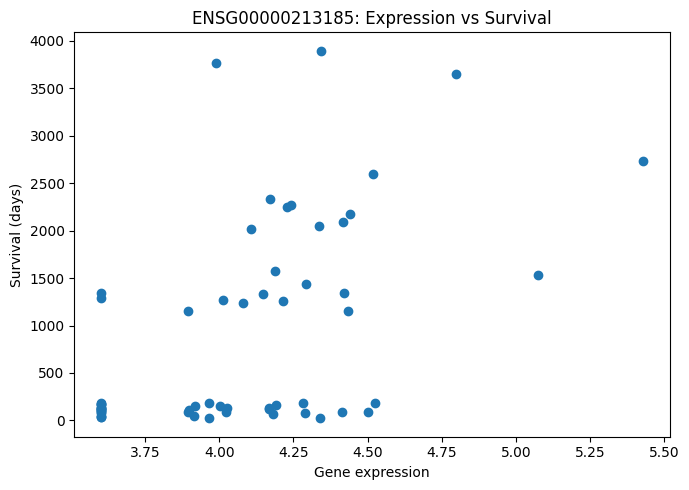

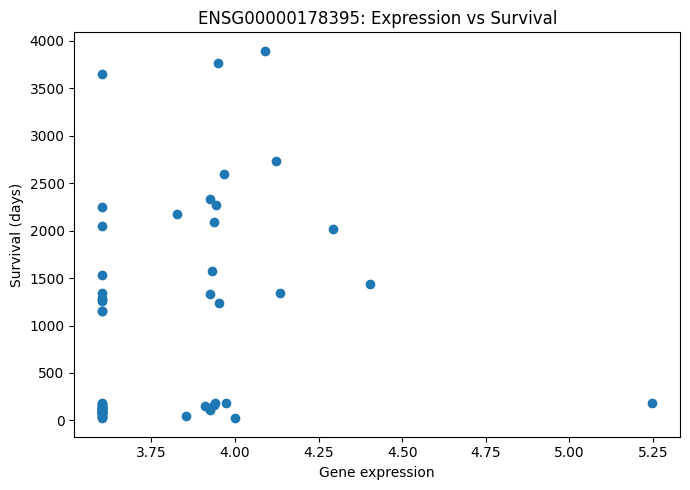

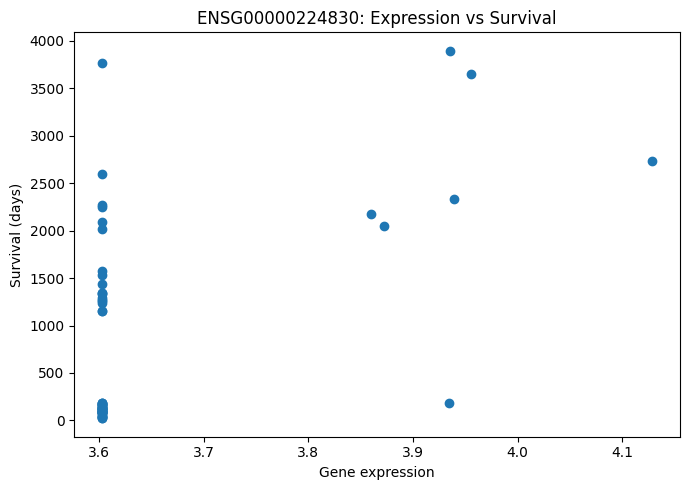

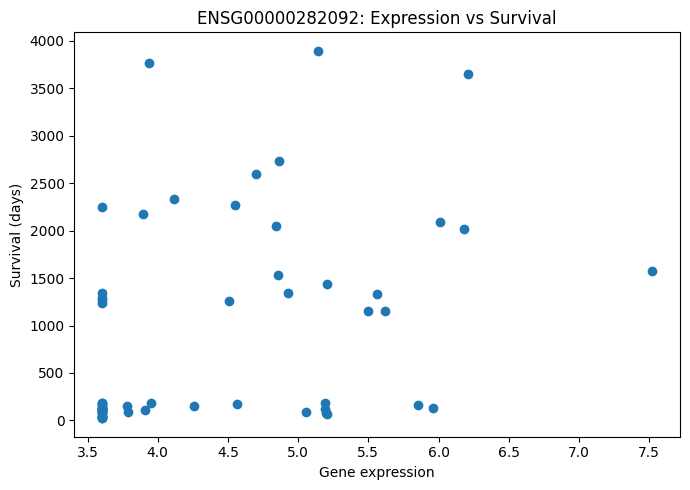

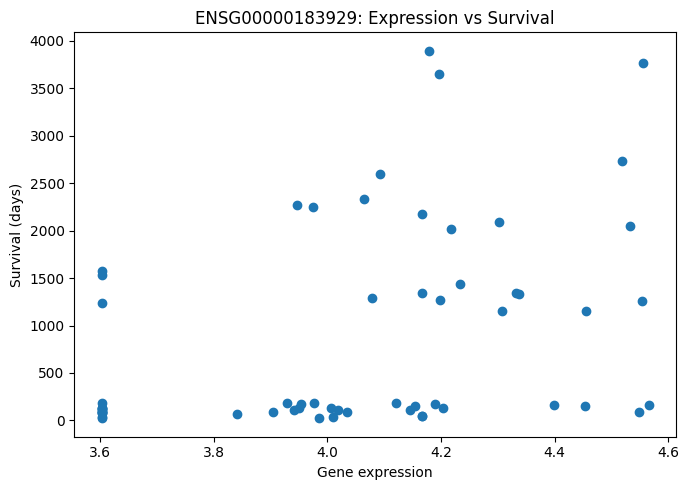

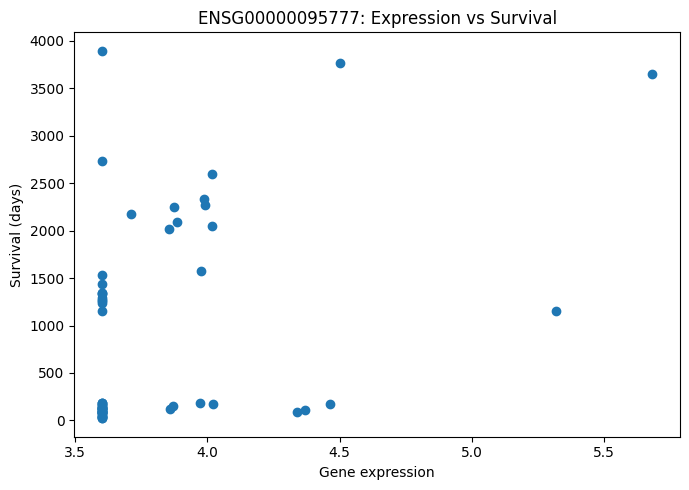

In [ ]:
import matplotlib.pyplot as plt

for gene in top_genes:
    x = expression_survival.loc[gene].astype(float).to_numpy()

    plt.figure(figsize=(7, 5))
    plt.scatter(x, survival)

    plt.xlabel("Gene expression")
    plt.ylabel("Survival (days)")
    plt.title(f"{gene}: Expression vs Survival")

    plt.tight_layout()
    plt.show()

In [ ]:
results.to_csv(
    f"{RESULTS_DIR}/gene_survival_associations.csv",
    index=False
)

ranked.to_csv(
    f"{RESULTS_DIR}/ranked_by_absolute_correlation.csv",
    index=False
)

print("Week 2 survival analysis results saved.")
print("Full results:", len(results), "genes")
print("Significant genes (FDR < 0.05):", len(significant))

Week 2 survival analysis results saved.
Full results: 30617 genes
Significant genes (FDR < 0.05): 0


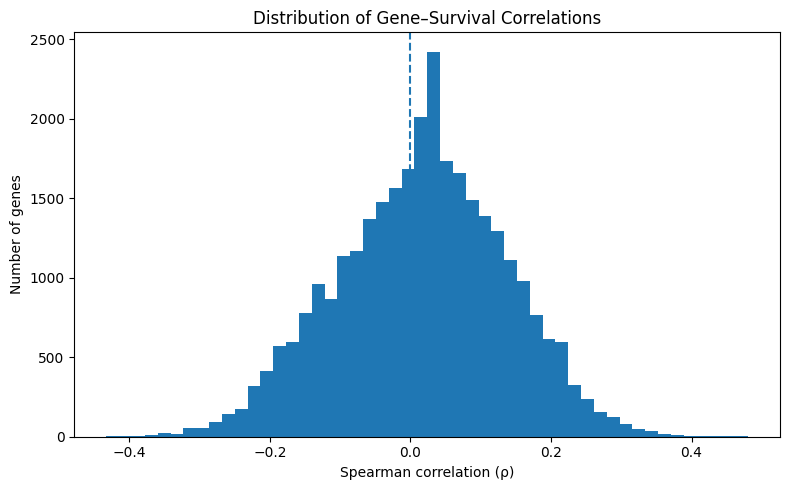

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    results["spearman_rho"],
    bins=50
)

plt.axvline(0, linestyle="--")

plt.xlabel("Spearman correlation (ρ)")
plt.ylabel("Number of genes")
plt.title("Distribution of Gene–Survival Correlations")

plt.tight_layout()
plt.show()

In [ ]:
print("Mean Spearman rho:", results["spearman_rho"].mean())
print("Median Spearman rho:", results["spearman_rho"].median())

print(
    "Positive correlations:",
    (results["spearman_rho"] > 0).sum()
)

print(
    "Negative correlations:",
    (results["spearman_rho"] < 0).sum()
)

Mean Spearman rho: 0.016360925242373748
Median Spearman rho: 0.02255589485443992
Positive correlations: 17623
Negative correlations: 12944


In [ ]:
summary = {
    "total_genes_tested": len(results),
    "constant_genes_removed": 6744,
    "samples_with_survival": len(survival),
    "significant_genes_FDR_0.05": len(significant),
    "mean_spearman_rho": results["spearman_rho"].mean(),
    "median_spearman_rho": results["spearman_rho"].median(),
    "positive_correlations": (results["spearman_rho"] > 0).sum(),
    "negative_correlations": (results["spearman_rho"] < 0).sum()
}

summary_df = pd.DataFrame([summary])

summary_df.to_csv(
    f"{RESULTS_DIR}/week2_summary.csv",
    index=False
)

print(summary_df.to_string(index=False))
print("\nWeek 2 summary saved.")

 total_genes_tested  constant_genes_removed  samples_with_survival  significant_genes_FDR_0.05  mean_spearman_rho  median_spearman_rho  positive_correlations  negative_correlations
              30617                    6744                     59                           0           0.016361             0.022556                  17623                  12944

Week 2 summary saved.


In [ ]:
# Check the format of our gene IDs

print("Example gene IDs:")
print(results["gene"].head(10).tolist())

print("\nTotal genes:")
print(len(results))

print("\nUnique genes:")
print(results["gene"].nunique())

Example gene IDs:
['ENSG00000213185', 'ENSG00000178395', 'ENSG00000224830', 'ENSG00000282092', 'ENSG00000183929', 'ENSG00000095777', 'ENSG00000061492', 'ENSG00000219992', 'ENSG00000276996', 'ENSG00000204257']

Total genes:
30617

Unique genes:
30617


In [ ]:
!pip install mygene

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 4.5 MB/s eta 0:00:00


In [ ]:
import mygene

mg = mygene.MyGeneInfo()

gene_ids = results["gene"].tolist()

annotations = mg.querymany(
    gene_ids,
    scopes="ensembl.gene",
    fields="symbol,name",
    species="human",
    as_dataframe=True
)

annotations = annotations.reset_index()

print("Annotations retrieved:", len(annotations))
print("\nColumns:")
print(annotations.columns.tolist())

print("\nExample annotations:")
print(
    annotations[
        ["query", "symbol", "name"]
    ].head(10).to_string(index=False)
)

INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:querying 5001-6000 ...
INFO:biothings.client:querying 6001-7000 ...
INFO:biothings.client:querying 7001-8000 ...
INFO:biothings.client:querying 8001-9000 ...
INFO:biothings.client:querying 9001-10000 ...
INFO:biothings.client:querying 10001-11000 ...
INFO:biothings.client:querying 11001-12000 ...
INFO:biothings.client:querying 12001-13000 ...
INFO:biothings.client:querying 13001-14000 ...
INFO:biothings.client:querying 14001-15000 ...
INFO:biothings.client:querying 15001-16000 ...
INFO:biothings.client:querying 16001-17000 ...
INFO:biothings.client:querying 17001-18000 ...
INFO:biothings.client:querying 18001-19000 ...
INFO:biothings.client:querying 19001-20000 ...
INFO:biothings.client:querying 20001-21000 ...
INFO:biothings.client:querying 2100

Annotations retrieved: 30630

Columns:
['query', '_id', '_score', 'name', 'symbol', 'notfound']

Example annotations:
          query  symbol                                                        name
ENSG00000213185  FAM24B                 family with sequence similarity 24 member B
ENSG00000178395 CCDC185                           coiled-coil domain containing 185
ENSG00000224830  OR2X1P olfactory receptor family 2 subfamily X member 1 pseudogene
ENSG00000282092   MED16                                 mediator complex subunit 16
ENSG00000183929 DUSP5P1                 dual specificity phosphatase 5 pseudogene 1
ENSG00000095777   MYO3A                                                 myosin IIIA
ENSG00000061492   WNT8A                                        Wnt family member 8A
ENSG00000219992     NaN                                                         NaN
ENSG00000276996  SLC6A3                            solute carrier family 6 member 3
ENSG00000204257 HLA-DMA        major histo

In [ ]:
# Keep only useful annotation columns
annotations_clean = annotations[
    ["query", "symbol", "name", "notfound"]
].copy()

# Remove duplicate annotation rows
annotations_clean = annotations_clean.drop_duplicates(
    subset=["query"],
    keep="first"
)

# Merge gene annotations into our survival results
annotated_results = results.merge(
    annotations_clean,
    left_on="gene",
    right_on="query",
    how="left"
)

# Remove redundant query column
annotated_results = annotated_results.drop(
    columns=["query"]
)

print("Annotated results shape:", annotated_results.shape)

print("\nGenes with symbols:")
print(
    annotated_results["symbol"].notna().sum()
)

print("\nGenes without symbols:")
print(
    annotated_results["symbol"].isna().sum()
)

print("\nExample:")
print(
    annotated_results[
        ["gene", "symbol", "name", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

Annotated results shape: (30617, 7)

Genes with symbols:
27929

Genes without symbols:
2688

Example:
           gene    symbol                                                        name  spearman_rho  p_value     FDR
ENSG00000213185    FAM24B                 family with sequence similarity 24 member B      0.480300 0.000118 0.99955
ENSG00000178395   CCDC185                           coiled-coil domain containing 185      0.472273 0.000159 0.99955
ENSG00000224830    OR2X1P olfactory receptor family 2 subfamily X member 1 pseudogene      0.459870 0.000248 0.99955
ENSG00000282092     MED16                                 mediator complex subunit 16      0.449726 0.000352 0.99955
ENSG00000183929   DUSP5P1                 dual specificity phosphatase 5 pseudogene 1      0.436445 0.000549 0.99955
ENSG00000095777     MYO3A                                                 myosin IIIA      0.436283 0.000552 0.99955
ENSG00000061492     WNT8A                                        Wnt family mem

In [ ]:
annotated_results.to_csv(
    f"{RESULTS_DIR}/annotated_gene_survival_associations.csv",
    index=False
)

print("Annotated results saved.")

Annotated results saved.


In [ ]:
# Keep genes with a recognized symbol
annotated_with_symbols = annotated_results[
    annotated_results["symbol"].notna()
].copy()

# Remove duplicate symbols so each symbol appears once
annotated_with_symbols = annotated_with_symbols.drop_duplicates(
    subset=["symbol"],
    keep="first"
)

# Rank by absolute correlation
annotated_ranked = annotated_with_symbols.sort_values(
    "spearman_rho",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

print("Genes with symbols:", len(annotated_ranked))

print("\nTop 30 annotated genes by absolute correlation:")
print(
    annotated_ranked[
        ["gene", "symbol", "name", "spearman_rho", "p_value", "FDR"]
    ].head(30).to_string(index=False)
)

Genes with symbols: 26710

Top 30 annotated genes by absolute correlation:
           gene    symbol                                                         name  spearman_rho  p_value     FDR
ENSG00000213185    FAM24B                  family with sequence similarity 24 member B      0.480300 0.000118 0.99955
ENSG00000178395   CCDC185                            coiled-coil domain containing 185      0.472273 0.000159 0.99955
ENSG00000224830    OR2X1P  olfactory receptor family 2 subfamily X member 1 pseudogene      0.459870 0.000248 0.99955
ENSG00000282092     MED16                                  mediator complex subunit 16      0.449726 0.000352 0.99955
ENSG00000183929   DUSP5P1                  dual specificity phosphatase 5 pseudogene 1      0.436445 0.000549 0.99955
ENSG00000095777     MYO3A                                                  myosin IIIA      0.436283 0.000552 0.99955
ENSG00000061492     WNT8A                                         Wnt family member 8A      0.43574

In [ ]:
positive_genes = annotated_results[
    annotated_results["spearman_rho"] > 0
].sort_values(
    "spearman_rho",
    ascending=False
)

negative_genes = annotated_results[
    annotated_results["spearman_rho"] < 0
].sort_values(
    "spearman_rho",
    ascending=True
)

print("TOP POSITIVE ASSOCIATIONS")
print(
    positive_genes[
        ["symbol", "name", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

print("\nTOP NEGATIVE ASSOCIATIONS")
print(
    negative_genes[
        ["symbol", "name", "spearman_rho", "p_value", "FDR"]
    ].head(20).to_string(index=False)
)

TOP POSITIVE ASSOCIATIONS
   symbol                                                         name  spearman_rho  p_value     FDR
   FAM24B                  family with sequence similarity 24 member B      0.480300 0.000118 0.99955
  CCDC185                            coiled-coil domain containing 185      0.472273 0.000159 0.99955
   OR2X1P  olfactory receptor family 2 subfamily X member 1 pseudogene      0.459870 0.000248 0.99955
    MED16                                  mediator complex subunit 16      0.449726 0.000352 0.99955
  DUSP5P1                  dual specificity phosphatase 5 pseudogene 1      0.436445 0.000549 0.99955
    MYO3A                                                  myosin IIIA      0.436283 0.000552 0.99955
    WNT8A                                         Wnt family member 8A      0.435744 0.000562 0.99955
   SLC6A3                             solute carrier family 6 member 3      0.425002 0.000793 0.99955
      NaN                                               

In [ ]:
# Create a ranked list of genes based on Spearman correlation

ranked_symbols = annotated_results[
    annotated_results["symbol"].notna()
].copy()

# Remove duplicate gene symbols
ranked_symbols = ranked_symbols.drop_duplicates(
    subset=["symbol"],
    keep="first"
)

# Sort from most positive to most negative correlation
ranked_symbols = ranked_symbols.sort_values(
    "spearman_rho",
    ascending=False
)

# Save ranked gene list
ranked_symbols[
    ["symbol", "spearman_rho", "p_value", "FDR"]
].to_csv(
    f"{RESULTS_DIR}/ranked_gene_symbols.csv",
    index=False
)

print("Ranked gene list created.")
print("Genes included:", len(ranked_symbols))

print("\nTop 10:")
print(
    ranked_symbols[
        ["symbol", "spearman_rho"]
    ].head(10).to_string(index=False)
)

print("\nBottom 10:")
print(
    ranked_symbols[
        ["symbol", "spearman_rho"]
    ].tail(10).to_string(index=False)
)

Ranked gene list created.
Genes included: 26710

Top 10:
   symbol  spearman_rho
   FAM24B      0.480300
  CCDC185      0.472273
   OR2X1P      0.459870
    MED16      0.449726
  DUSP5P1      0.436445
    MYO3A      0.436283
    WNT8A      0.435744
   SLC6A3      0.425002
GOLGA6L10      0.404209
  SNRPCP6      0.399644

Bottom 10:
   symbol  spearman_rho
     SSX4     -0.382211
   ST13P7     -0.382232
SELENOTP1     -0.390649
    LYZL4     -0.393617
 MTCO3P11     -0.398605
   LSM1P1     -0.400630
      B2M     -0.403206
  RPSAP22     -0.408435
    ADAM9     -0.420171
  HLA-DMA     -0.422471


In [ ]:
!pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 43.0 MB/s eta 0:00:00


In [ ]:
import gseapy as gp

print("GSEApy version:", gp.__version__)

GSEApy version: 1.3.1


In [ ]:
print("Genes in ranked list:", len(ranked_symbols))

print("\nTop 10:")
print(
    ranked_symbols[
        ["symbol", "spearman_rho"]
    ].head(10).to_string(index=False)
)

print("\nBottom 10:")
print(
    ranked_symbols[
        ["symbol", "spearman_rho"]
    ].tail(10).to_string(index=False)
)

Genes in ranked list: 26710

Top 10:
   symbol  spearman_rho
   FAM24B      0.480300
  CCDC185      0.472273
   OR2X1P      0.459870
    MED16      0.449726
  DUSP5P1      0.436445
    MYO3A      0.436283
    WNT8A      0.435744
   SLC6A3      0.425002
GOLGA6L10      0.404209
  SNRPCP6      0.399644

Bottom 10:
   symbol  spearman_rho
     SSX4     -0.382211
   ST13P7     -0.382232
SELENOTP1     -0.390649
    LYZL4     -0.393617
 MTCO3P11     -0.398605
   LSM1P1     -0.400630
      B2M     -0.403206
  RPSAP22     -0.408435
    ADAM9     -0.420171
  HLA-DMA     -0.422471


In [ ]:
import gseapy as gp

go_results = gp.prerank(
    rnk=ranked_symbols[["symbol", "spearman_rho"]],
    gene_sets="GO_Biological_Process_2023",
    permutation_num=1000,
    outdir=None,
    seed=42,
    verbose=True
)

print("GO analysis complete.")

2026-09-21 18:09:03,871 [WARNING] Duplicated values found in preranked stats: 20.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-09-21 18:09:03,873 [INFO] Parsing data files for GSEA.............................
2026-09-21 18:09:03,955 [INFO] Enrichr library gene sets already downloaded in: /root/.cache/gseapy, use local file
2026-09-21 18:09:04,131 [INFO] 2697 gene_sets have been filtered out when max_size=500 and min_size=15
2026-09-21 18:09:04,134 [INFO] 2710 gene_sets used for further statistical testing.....
2026-09-21 18:09:04,136 [INFO] Start to run GSEA...Might take a while..................
2026-09-21 18:16:23,616 [INFO] Congratulations. GSEApy runs successfully................



GO analysis complete.


In [ ]:
go_df = go_results.res2d.copy()

print("Number of pathways tested:", len(go_df))

print("\nColumns:")
print(go_df.columns.tolist())

print("\nTop pathways:")
print(
    go_df.head(20).to_string(index=False)
)

Number of pathways tested: 2710

Columns:
['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']

Top pathways:
   Name                                                                                              Term        ES       NES  NOM p-val  FDR q-val  FWER p-val   Tag % Gene %                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [ ]:
PATHWAY_DIR = f"{RESULTS_DIR}/pathways"
import os

os.makedirs(PATHWAY_DIR, exist_ok=True)

go_df.to_csv(
    f"{PATHWAY_DIR}/GO_Biological_Process_prerank.csv",
    index=False
)

print("GO pathway results saved.")

GO pathway results saved.


In [ ]:
significant_pathways = go_df[
    go_df["FDR q-val"] < 0.05
].copy()

significant_pathways = significant_pathways.sort_values(
    "NES",
    ascending=False
)

print(
    "Significant pathways (FDR < 0.05):",
    len(significant_pathways)
)

print(
    significant_pathways[
        [
            "Term",
            "NES",
            "NOM p-val",
            "FDR q-val",
            "FWER p-val"
        ]
    ].head(30).to_string(index=False)
)

Significant pathways (FDR < 0.05): 63
                                                                                             Term      NES  NOM p-val  FDR q-val  FWER p-val
                                                           Mitochondrial Translation (GO:0032543) 2.342555   0.000000   0.000000       0.000
                                                       Mitochondrial Gene Expression (GO:0140053) 2.290614   0.000000   0.000898       0.002
                                                                Chromatin Remodeling (GO:0006338) 2.143278   0.000000   0.006288       0.020
                                                      mRNA Splicing, Via Spliceosome (GO:0000398) 2.115800   0.000000   0.007410       0.032
RNA Splicing, Via Transesterification Reactions With Bulged Adenosine As Nucleophile (GO:0000377) 2.112463   0.000000   0.006108       0.033
                                          Monoubiquitinated Protein Deubiquitination (GO:0035520) 2.082148   0.00000

In [ ]:
positive_pathways = significant_pathways[
    significant_pathways["NES"] > 0
].copy()

negative_pathways = significant_pathways[
    significant_pathways["NES"] < 0
].copy()

print("POSITIVE ENRICHMENT")
print(
    positive_pathways[
        ["Term", "NES", "FDR q-val"]
    ].head(20).to_string(index=False)
)

print("\nNEGATIVE ENRICHMENT")
print(
    negative_pathways[
        ["Term", "NES", "FDR q-val"]
    ].head(20).to_string(index=False)
)

POSITIVE ENRICHMENT
                                                                                             Term      NES  FDR q-val
                                                           Mitochondrial Translation (GO:0032543) 2.342555   0.000000
                                                       Mitochondrial Gene Expression (GO:0140053) 2.290614   0.000898
                                                                Chromatin Remodeling (GO:0006338) 2.143278   0.006288
                                                      mRNA Splicing, Via Spliceosome (GO:0000398) 2.115800   0.007410
RNA Splicing, Via Transesterification Reactions With Bulged Adenosine As Nucleophile (GO:0000377) 2.112463   0.006108
                                          Monoubiquitinated Protein Deubiquitination (GO:0035520) 2.082148   0.007635
                                                              Chromatin Organization (GO:0006325) 2.079786   0.006544
                      Positive Regul

In [ ]:
PATHWAY_DIR = f"{RESULTS_DIR}/pathways"

go_df.to_csv(
    f"{PATHWAY_DIR}/GO_Biological_Process_prerank.csv",
    index=False
)

print("Saved.")

Saved.


In [ ]:
import pandas as pd

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "GO_Biological_Process_prerank.csv":
            print(os.path.join(root, file))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "GO_Biological_Process_prerank.csv":
            print(os.path.join(root, file))

/content/drive/MyDrive/GSE149009/results/survival/pathways/GO_Biological_Process_prerank.csv


In [ ]:
import pandas as pd

PATHWAY_FILE = "/content/drive/MyDrive/GSE149009/results/survival/pathways/GO_Biological_Process_prerank.csv"

pathways = pd.read_csv(PATHWAY_FILE)

# Keep pathways with FDR < 0.05
sig = pathways[pathways["FDR q-val"] < 0.05].copy()

print("Total pathways tested:", len(pathways))
print("Significant pathways:", len(sig))

display(sig.head(20))

Total pathways tested: 2710
Significant pathways: 63


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Mitochondrial Translation (GO:0032543),0.555473,2.342555,0.000000,0.000000,0.000,59/98,29.22%,GATB;MRPL57;GATC;MRPL19;MRPL16;MRPS6;MRPS21;MR...
1,prerank,Mitochondrial Gene Expression (GO:0140053),0.536896,2.290614,0.000000,0.000898,0.002,64/103,30.40%,GATB;MRPL57;GATC;MRPL19;MRPL16;MRPS6;MRPS21;MR...
2,prerank,Positive Regulation Of Pattern Recognition Rec...,-0.552210,-2.227079,0.000000,0.044575,0.035,23/39,25.45%,SLC15A4;RSAD2;DHX58;TRIM3;OASL;DDX60;TLR2;TLR1...
3,prerank,Immunoglobulin Mediated Immune Response (GO:00...,-0.590523,-2.189335,0.000000,0.039153,0.060,16/30,13.42%,HLA-DMA;HLA-DRB4;HLA-DQA1;HLA-DQA2;HLA-DMB;HLA...
4,prerank,Defense Response To Symbiont (GO:0140546),-0.417701,-2.167732,0.000000,0.034535,0.077,62/147,20.31%,PTPRC;APOBEC3A;RSAD2;SLFN11;IFNL4;IRF7;SLFN13;...
5,prerank,Chromatin Remodeling (GO:0006338),0.456499,2.143278,0.000000,0.006288,0.020,124/227,31.12%,MCM3AP;APLF;DPF2;TADA2B;DAXX;MIER1;CTCF;PWWP2B...
6,prerank,Activation Of Adenylate Cyclase Activity (GO:0...,-0.628897,-2.135320,0.000000,0.039455,0.114,9/20,10.81%,P2RY11;CALCR;EDNRA;ADRB1;TMIGD3;ADRB2;CRHR1;DR...
7,prerank,"mRNA Splicing, Via Spliceosome (GO:0000398)",0.451298,2.115800,0.000000,0.007410,0.032,108/209,32.47%,RBMX2;USP49;RBM17;HNRNPH3;SNRNP70;IK;RBM41;HTA...
8,prerank,Negative Regulation Of Chemokine Production (G...,-0.691300,-2.114433,0.000000,0.039997,0.141,9/16,13.98%,GSTP1;OAS1;LILRB4;ELANE;MAP2K5;MUL1;SIGIRR;IL6...
9,prerank,"RNA Splicing, Via Transesterification Reaction...",0.461350,2.112463,0.000000,0.006108,0.033,94/178,32.47%,RBMX2;USP49;HNRNPH3;SNRNP70;IK;RBM41;HTATSF1;P...


In [ ]:
# Broad biological themes
theme_keywords = {
    "Mitochondrial biology": [
        "mitochondrial"
    ],

    "RNA processing / splicing": [
        "rna splicing",
        "mrna splicing",
        "mrna processing",
        "spliceosome",
        "transesterification"
    ],

    "Chromatin / epigenetic regulation": [
        "chromatin",
        "nucleosome",
        "histone"
    ],

    "Transcription": [
        "transcription",
        "rna polymerase"
    ],

    "DNA / genome regulation": [
        "dna repair",
        "dna metabolic",
        "double-strand break",
        "genome"
    ],

    "Immune / inflammatory processes": [
        "immune",
        "interferon",
        "antigen",
        "pattern recognition",
        "defense response",
        "chemokine"
    ]
}


def assign_theme(term):
    term = term.lower()

    matches = []

    for theme, keywords in theme_keywords.items():
        if any(keyword in term for keyword in keywords):
            matches.append(theme)

    if matches:
        return "; ".join(matches)
    else:
        return "Other"


# Assign themes
sig["theme"] = sig["Term"].apply(assign_theme)


# Create organized table
theme_table = sig[
    [
        "Name",
        "Term",
        "NES",
        "NOM p-val",
        "FDR q-val",
        "FWER p-val",
        "Lead_genes",
        "theme"
    ]
].sort_values("FDR q-val")


# Save
THEME_FILE = "/content/drive/MyDrive/GSE149009/results/survival/pathways/pathway_themes.csv"

theme_table.to_csv(
    THEME_FILE,
    index=False
)


print("Saved:", THEME_FILE)

print("\nTheme counts:")
print(theme_table["theme"].value_counts())

print("\nTop significant pathways:")
display(theme_table.head(20))

Saved: /content/drive/MyDrive/GSE149009/results/survival/pathways/pathway_themes.csv

Theme counts:
theme
Other                                                         23
Transcription                                                 12
Chromatin / epigenetic regulation                              9
DNA / genome regulation                                        6
Immune / inflammatory processes                                6
RNA processing / splicing                                      4
Mitochondrial biology                                          2
Chromatin / epigenetic regulation; DNA / genome regulation     1
Name: count, dtype: int64

Top significant pathways:


,Name,Term,NES,NOM p-val,FDR q-val,FWER p-val,Lead_genes,theme
0,prerank,Mitochondrial Translation (GO:0032543),2.342555,0.0,0.000000,0.000,GATB;MRPL57;GATC;MRPL19;MRPL16;MRPS6;MRPS21;MR...,Mitochondrial biology
1,prerank,Mitochondrial Gene Expression (GO:0140053),2.290614,0.0,0.000898,0.002,GATB;MRPL57;GATC;MRPL19;MRPL16;MRPS6;MRPS21;MR...,Mitochondrial biology
9,prerank,"RNA Splicing, Via Transesterification Reaction...",2.112463,0.0,0.006108,0.033,RBMX2;USP49;HNRNPH3;SNRNP70;IK;RBM41;HTATSF1;P...,RNA processing / splicing
5,prerank,Chromatin Remodeling (GO:0006338),2.143278,0.0,0.006288,0.020,MCM3AP;APLF;DPF2;TADA2B;DAXX;MIER1;CTCF;PWWP2B...,Chromatin / epigenetic regulation
13,prerank,Chromatin Organization (GO:0006325),2.079786,0.0,0.006544,0.049,H3-4;DPF2;TADA2B;DAXX;MIER1;CTCF;PWWP2B;SIRT1;...,Chromatin / epigenetic regulation
14,prerank,Positive Regulation Of DNA-templated Transcrip...,2.069829,0.0,0.007186,0.059,MED16;THOC1;MED20;PWWP2B;MED30;MED28;MED1;DDX3...,Transcription
7,prerank,"mRNA Splicing, Via Spliceosome (GO:0000398)",2.115800,0.0,0.007410,0.032,RBMX2;USP49;RBM17;HNRNPH3;SNRNP70;IK;RBM41;HTA...,RNA processing / splicing
11,prerank,Monoubiquitinated Protein Deubiquitination (GO...,2.082148,0.0,0.007635,0.049,ENY2;TADA2B;SUPT3H;TAF5L;SUPT7L;KAT2A;TAF5;TAF...,Other
16,prerank,Regulation Of Transcription Elongation By RNA ...,2.055418,0.0,0.007815,0.081,MED16;MED20;PWWP2B;MED30;INTS2;INTS3;MED28;MED...,Transcription
15,prerank,mRNA Processing (GO:0006397),2.060203,0.0,0.007885,0.074,RBMX2;USP49;PRPF18;KIN;HNRNPH3;SNRNP70;IK;RBM4...,RNA processing / splicing


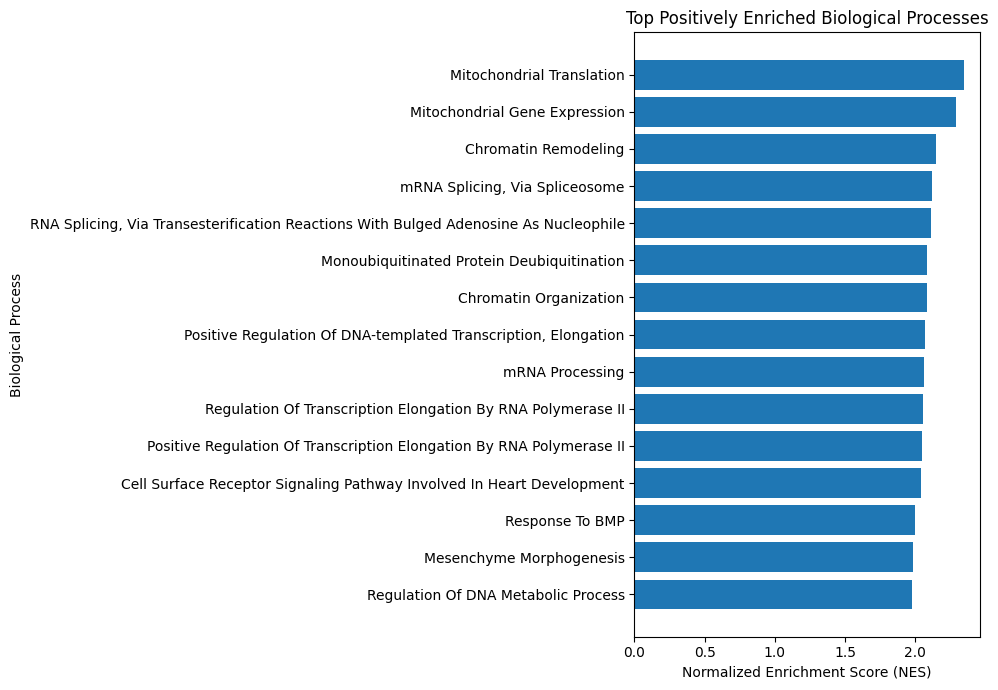

Saved: /content/drive/MyDrive/GSE149009/results/survival/pathways/top_positive_pathways.png


In [ ]:
import matplotlib.pyplot as plt

# Make a copy of significant pathways
plot_df = sig.copy()

# Clean pathway names for plotting
plot_df["short_term"] = (
    plot_df["Term"]
    .str.replace(r"\s*\(GO:\d+\)", "", regex=True)
)

# -----------------------------
# Top positive pathways
# -----------------------------

positive = (
    plot_df[plot_df["NES"] > 0]
    .sort_values("NES", ascending=False)
    .head(15)
    .sort_values("NES")
)

plt.figure(figsize=(10, 7))

plt.barh(
    positive["short_term"],
    positive["NES"]
)

plt.xlabel("Normalized Enrichment Score (NES)")
plt.ylabel("Biological Process")
plt.title("Top Positively Enriched Biological Processes")

plt.tight_layout()

positive_fig = "/content/drive/MyDrive/GSE149009/results/survival/pathways/top_positive_pathways.png"
plt.savefig(positive_fig, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", positive_fig)

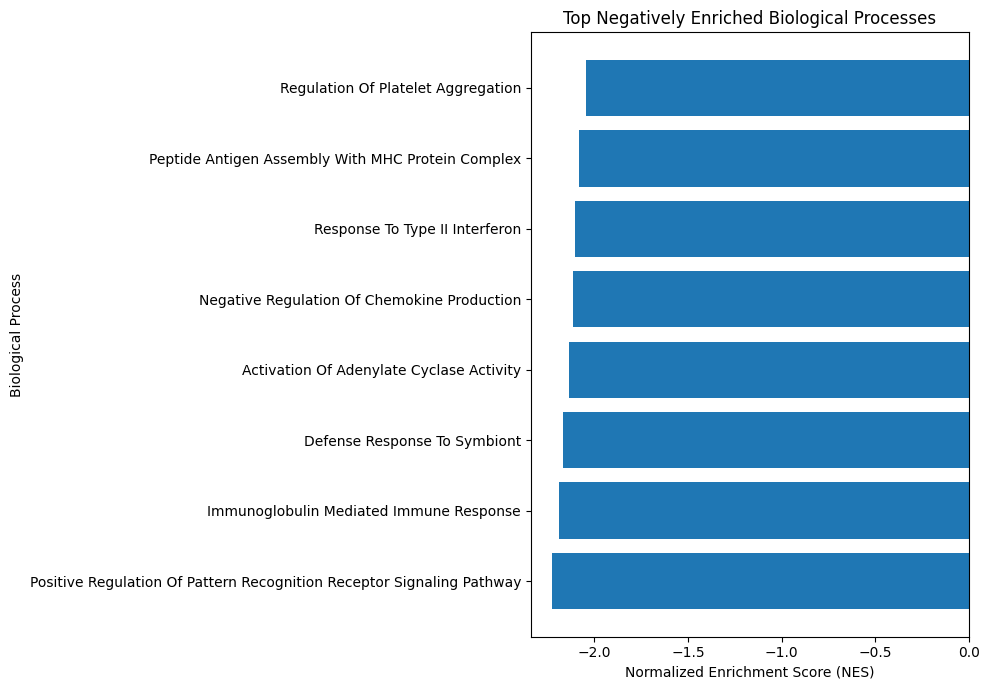

Saved: /content/drive/MyDrive/GSE149009/results/survival/pathways/top_negative_pathways.png


In [ ]:
# -----------------------------
# Top negative pathways
# -----------------------------

negative = (
    plot_df[plot_df["NES"] < 0]
    .sort_values("NES")
    .head(15)
    .sort_values("NES")
)

plt.figure(figsize=(10, 7))

plt.barh(
    negative["short_term"],
    negative["NES"]
)

plt.xlabel("Normalized Enrichment Score (NES)")
plt.ylabel("Biological Process")
plt.title("Top Negatively Enriched Biological Processes")

plt.tight_layout()

negative_fig = "/content/drive/MyDrive/GSE149009/results/survival/pathways/top_negative_pathways.png"
plt.savefig(negative_fig, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", negative_fig)

In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive/GSE149009"):
    for file in files:
        if "ranked_gene" in file.lower() or "annotated_gene" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/GSE149009/results/survival/annotated_gene_survival_associations.csv
/content/drive/MyDrive/GSE149009/results/survival/ranked_gene_symbols.csv


In [ ]:
import pandas as pd

RANKED_FILE = "/content/drive/MyDrive/GSE149009/results/survival/ranked_gene_symbols.csv"

ranked_symbols = pd.read_csv(RANKED_FILE)

print("Shape:", ranked_symbols.shape)
print("Columns:")
print(ranked_symbols.columns.tolist())
print("\nFirst 5 rows:")
display(ranked_symbols.head())

Shape: (26710, 4)
Columns:
['symbol', 'spearman_rho', 'p_value', 'FDR']

First 5 rows:


,symbol,spearman_rho,p_value,FDR
0,FAM24B,0.480300,0.000118,0.99955
1,CCDC185,0.472273,0.000159,0.99955
2,OR2X1P,0.459870,0.000248,0.99955
3,MED16,0.449726,0.000352,0.99955
4,DUSP5P1,0.436445,0.000549,0.99955


In [ ]:
ANNOTATED_FILE = "/content/drive/MyDrive/GSE149009/results/survival/annotated_gene_survival_associations.csv"

annotated = pd.read_csv(ANNOTATED_FILE)

print("Shape:", annotated.shape)
print("Columns:")
print(annotated.columns.tolist())

display(annotated.head())

Shape: (30617, 7)
Columns:
['gene', 'spearman_rho', 'p_value', 'FDR', 'symbol', 'name', 'notfound']


,gene,spearman_rho,p_value,FDR,symbol,name,notfound
0,ENSG00000213185,0.480300,0.000118,0.99955,FAM24B,family with sequence similarity 24 member B,NaN
1,ENSG00000178395,0.472273,0.000159,0.99955,CCDC185,coiled-coil domain containing 185,NaN
2,ENSG00000224830,0.459870,0.000248,0.99955,OR2X1P,olfactory receptor family 2 subfamily X member...,NaN
3,ENSG00000282092,0.449726,0.000352,0.99955,MED16,mediator complex subunit 16,NaN
4,ENSG00000183929,0.436445,0.000549,0.99955,DUSP5P1,dual specificity phosphatase 5 pseudogene 1,NaN


In [ ]:
import requests
import pandas as pd
import time

gene_ids = annotated["gene"].dropna().unique().tolist()

print("Genes to classify:", len(gene_ids))

url = "https://rest.ensembl.org/lookup/id"

headers = {
    "Content-Type": "application/json",
    "Accept": "application/json"
}

biotype_records = []

for i in range(0, len(gene_ids), 1000):

    batch = gene_ids[i:i+1000]

    response = requests.post(
        url,
        headers=headers,
        json={"ids": batch}
    )

    if response.status_code != 200:
        print(f"Error on batch {i//1000 + 1}: {response.status_code}")
        continue

    data = response.json()

    for gene_id, info in data.items():

        # Some Ensembl IDs may return None
        if info is None:
            biotype = None
        else:
            biotype = info.get("biotype")

        biotype_records.append({
            "gene": gene_id,
            "biotype": biotype
        })

    print(f"Processed {min(i+1000, len(gene_ids))}/{len(gene_ids)}")

    time.sleep(0.2)

biotype_df = pd.DataFrame(biotype_records)

print("\nGenes returned:", len(biotype_df))

print("\nBiotype counts:")
print(biotype_df["biotype"].value_counts(dropna=False))

Genes to classify: 30617
Processed 1000/30617
Processed 2000/30617
Processed 3000/30617
Processed 4000/30617
Processed 5000/30617
Processed 6000/30617
Processed 7000/30617
Processed 8000/30617
Processed 9000/30617
Processed 10000/30617
Processed 11000/30617
Processed 12000/30617
Processed 13000/30617
Processed 14000/30617
Processed 15000/30617
Processed 16000/30617
Processed 17000/30617
Processed 18000/30617
Processed 19000/30617
Processed 20000/30617
Processed 21000/30617
Processed 22000/30617
Processed 23000/30617
Processed 24000/30617
Processed 25000/30617
Processed 26000/30617
Processed 27000/30617
Processed 28000/30617
Processed 29000/30617
Processed 30000/30617
Processed 30617/30617

Genes returned: 30617

Biotype counts:
biotype
protein_coding                        20382
processed_pseudogene                   5856
transcribed_unprocessed_pseudogene     1265
unprocessed_pseudogene                 1063
transcribed_processed_pseudogene        908
None                              

In [ ]:
# Merge biotype information with the original gene-level results
validated = annotated.merge(
    biotype_df,
    on="gene",
    how="left"
)

print("Original genes:", len(validated))

# Keep protein-coding genes only
protein_coding = validated[
    validated["biotype"] == "protein_coding"
].copy()

print("Protein-coding genes:", len(protein_coding))

# Remove genes without a mapped symbol
protein_coding = protein_coding[
    protein_coding["symbol"].notna()
].copy()

# Remove duplicate symbols, keeping the strongest absolute correlation
protein_coding["abs_rho"] = protein_coding["spearman_rho"].abs()

protein_coding = (
    protein_coding
    .sort_values("abs_rho", ascending=False)
    .drop_duplicates("symbol")
    .copy()
)

print("Unique protein-coding symbols:", len(protein_coding))

display(
    protein_coding[
        ["gene", "symbol", "biotype", "spearman_rho", "p_value", "FDR"]
    ].head(10)
)

Original genes: 30617
Protein-coding genes: 20382
Unique protein-coding symbols: 19038


,gene,symbol,biotype,spearman_rho,p_value,FDR
0,ENSG00000213185,FAM24B,protein_coding,0.480300,0.000118,0.99955
1,ENSG00000178395,CCDC185,protein_coding,0.472273,0.000159,0.99955
3,ENSG00000282092,MED16,protein_coding,0.449726,0.000352,0.99955
5,ENSG00000095777,MYO3A,protein_coding,0.436283,0.000552,0.99955
6,ENSG00000061492,WNT8A,protein_coding,0.435744,0.000562,0.99955
8,ENSG00000276996,SLC6A3,protein_coding,0.425002,0.000793,0.99955
9,ENSG00000204257,HLA-DMA,protein_coding,-0.422471,0.000859,0.99955
10,ENSG00000282230,ADAM9,protein_coding,-0.420171,0.000923,0.99955
14,ENSG00000278662,GOLGA6L10,protein_coding,0.404209,0.001498,0.99955
15,ENSG00000273686,B2M,protein_coding,-0.403206,0.001543,0.99955


In [ ]:
!pip -q install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 5.6 MB/s eta 0:00:00


In [ ]:
import gseapy as gp

protein_ranking = protein_coding[
    ["symbol", "spearman_rho"]
].copy()

protein_ranking = protein_ranking.sort_values(
    "spearman_rho",
    ascending=False
)

print("Genes in protein-coding ranking:", len(protein_ranking))

protein_gsea = gp.prerank(
    rnk=protein_ranking,
    gene_sets="GO_Biological_Process_2023",
    permutation_num=1000,
    seed=42,
    outdir=None,
    verbose=False
)

protein_pathways = protein_gsea.res2d.copy()

print("Pathways tested:", len(protein_pathways))

display(
    protein_pathways[
        ["Term", "NES", "NOM p-val", "FDR q-val"]
    ].head(20)
)

2026-09-30 14:58:52,502 [WARNING] Duplicated values found in preranked stats: 14.54% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Genes in protein-coding ranking: 19038
Pathways tested: 2701


,Term,NES,NOM p-val,FDR q-val
0,Positive Regulation Of Pattern Recognition Rec...,-2.364768,0.000000,0.008348
1,Defense Response To Symbiont (GO:0140546),-2.337118,0.000000,0.012522
2,Immunoglobulin Mediated Immune Response (GO:00...,-2.306079,0.000000,0.011687
3,Response To Type II Interferon (GO:0034341),-2.305352,0.000000,0.009600
4,Activation Of Adenylate Cyclase Activity (GO:0...,-2.235586,0.000000,0.018032
5,Negative Regulation Of Chemokine Production (G...,-2.225633,0.000000,0.017253
6,Mitochondrial Translation (GO:0032543),2.209861,0.000000,0.000757
7,Peptide Antigen Assembly With MHC Protein Comp...,-2.204152,0.000000,0.017173
8,Positive Regulation Of B Cell Proliferation (G...,-2.180949,0.003546,0.019618
9,Platelet Aggregation (GO:0070527),-2.170765,0.000000,0.018922


In [ ]:
PROTEIN_PATHWAY_FILE = "/content/drive/MyDrive/GSE149009/results/survival/pathways/GO_Biological_Process_protein_coding_prerank.csv"

protein_pathways.to_csv(
    PROTEIN_PATHWAY_FILE,
    index=False
)

print("Saved:", PROTEIN_PATHWAY_FILE)

Saved: /content/drive/MyDrive/GSE149009/results/survival/pathways/GO_Biological_Process_protein_coding_prerank.csv


In [ ]:
# Show significant protein-coding pathways
protein_sig = protein_pathways[
    protein_pathways["FDR q-val"] < 0.05
].copy()

print("Significant protein-coding pathways:", len(protein_sig))

display(
    protein_sig[
        ["Term", "NES", "NOM p-val", "FDR q-val"]
    ].head(30)
)

Significant protein-coding pathways: 75


,Term,NES,NOM p-val,FDR q-val
0,Positive Regulation Of Pattern Recognition Rec...,-2.364768,0.000000,0.008348
1,Defense Response To Symbiont (GO:0140546),-2.337118,0.000000,0.012522
2,Immunoglobulin Mediated Immune Response (GO:00...,-2.306079,0.000000,0.011687
3,Response To Type II Interferon (GO:0034341),-2.305352,0.000000,0.009600
4,Activation Of Adenylate Cyclase Activity (GO:0...,-2.235586,0.000000,0.018032
5,Negative Regulation Of Chemokine Production (G...,-2.225633,0.000000,0.017253
6,Mitochondrial Translation (GO:0032543),2.209861,0.000000,0.000757
7,Peptide Antigen Assembly With MHC Protein Comp...,-2.204152,0.000000,0.017173
8,Positive Regulation Of B Cell Proliferation (G...,-2.180949,0.003546,0.019618
9,Platelet Aggregation (GO:0070527),-2.170765,0.000000,0.018922


In [ ]:
# Load the original Week 3 GSEA results
ORIGINAL_PATHWAY_FILE = (
    "/content/drive/MyDrive/GSE149009/results/survival/pathways/"
    "GO_Biological_Process_prerank.csv"
)

original_pathways = pd.read_csv(ORIGINAL_PATHWAY_FILE)

# Keep only the columns needed for comparison
original_compare = original_pathways[
    ["Term", "NES", "FDR q-val"]
].rename(columns={
    "NES": "NES_original",
    "FDR q-val": "FDR_original"
})

protein_compare = protein_pathways[
    ["Term", "NES", "FDR q-val"]
].rename(columns={
    "NES": "NES_protein_coding",
    "FDR q-val": "FDR_protein_coding"
})

# Match pathways present in both analyses
comparison = original_compare.merge(
    protein_compare,
    on="Term",
    how="inner"
)

# Determine significance in each analysis
comparison["sig_original"] = comparison["FDR_original"] < 0.05
comparison["sig_protein_coding"] = comparison["FDR_protein_coding"] < 0.05

print("Pathways in original:", len(original_compare))
print("Pathways in protein-coding:", len(protein_compare))
print("Pathways in both:", len(comparison))

print("\nSignificant in original:",
      comparison["sig_original"].sum())

print("Significant in protein-coding:",
      comparison["sig_protein_coding"].sum())

print("Significant in BOTH:",
      (
          comparison["sig_original"] &
          comparison["sig_protein_coding"]
      ).sum()
)

Pathways in original: 2710
Pathways in protein-coding: 2701
Pathways in both: 2701

Significant in original: 63
Significant in protein-coding: 75
Significant in BOTH: 29


In [ ]:
shared_sig["same_direction"] = (
    shared_sig["NES_original"] *
    shared_sig["NES_protein_coding"] > 0
)

print(
    "Shared significant pathways:",
    len(shared_sig)
)

print(
    "Same NES direction:",
    shared_sig["same_direction"].sum()
)

print(
    "Opposite NES direction:",
    (~shared_sig["same_direction"]).sum()
)

display(
    shared_sig[
        [
            "Term",
            "NES_original",
            "NES_protein_coding",
            "FDR_original",
            "FDR_protein_coding",
            "same_direction"
        ]
    ]
)

NameError: name 'shared_sig' is not defined